# 31 · Capstone: a reasoning model from scratch (mini-R1)

DeepSeek-R1, OpenAI's o-series and Claude's extended thinking are **reasoning models**. Before answering, they write a chain of thought, and they are better at problems with a checkable answer because of it. Notebook 15 showed that this works, and notebook 14 showed the training method, but on models someone else had pretrained.

This notebook puts the whole recipe together on a model built from scratch: the course's own `TransformerLM` (notebooks 02–05 and 08). It has 1.6M parameters and trains in minutes on a laptop GPU:

| stage | what it does here | in R1 | in the course |
|---|---|---|---|
| **pretraining** | next-token training on a "web" of solved problems: 90% give only the answer, 10% show the work | the base model (DeepSeek-V3) | 01, 08 |
| **R1-Zero** | RL with a verifier, straight from the base model; no reasoning examples | DeepSeek-R1-Zero | 14 |
| **cold start** | SFT on 300 worked solutions | a few thousand long chain-of-thought examples | 13 |
| **R1** | the same RL, after the cold start | DeepSeek-R1 | 14 |
| **control** | more SFT on the same 300 solutions, with the same compute as the RL | | |

**The task** is a chain of operations on one digit, modulo 10, evaluated left to right: `5+3*2-4=` means ((5 + 3) × 2 − 4) mod 10 = 2. A **verifier** (five lines of code) checks the final answer. Like the math and code problems reasoning models are trained on, the task is easy to check and hard to answer in one step.

**What we measure:**
- the accuracy of each model, with 95% intervals;
- how often the model *chooses* to reason, and how long its answers are, during RL;
- accuracy by chain length, including chains longer than any seen in training.

**Sources.** DeepSeek-AI (2025), *DeepSeek-R1: Incentivizing Reasoning Capability in LLMs via Reinforcement Learning*; Shao et al. (2024), *DeepSeekMath* (GRPO); Nye et al. (2021), *Show Your Work: Scratchpads for Intermediate Computation with Language Models*; Wei et al. (2022), *Chain-of-Thought Prompting*; Zelikman et al. (2022), *STaR*; Pan et al. (2025), *TinyZero*.

## Background: how a reasoning model is made

### Why writing the steps helps

A transformer computes each token in a fixed number of layers. A problem that needs many *sequential* steps, like a chain of operations where each one depends on the previous result, does not fit in one forward pass once the chain is long enough. Writing the intermediate results changes that. Each step becomes a short computation over tokens the model has already written, and the generated text acts as working memory. That is the scratchpad result of Nye et al. (2021), and the reason chain of thought lifted `qwen2.5:3b` from 12.5% to 85% on GSM8K in notebook 15.

### The R1 recipe

1. **A base model.** Pretraining on web text gives a model that has seen worked solutions, but mostly answers directly: on the web most answers come without their working.
2. **R1-Zero: RL from the base, with only a verifier.** For each problem the model samples several answers, a program checks each one, and the policy is pushed towards the answers that scored better than their siblings. Nobody shows the model how to reason.

   DeepSeek reported that R1-Zero learned to think longer on its own, and that it started to check and correct itself (the "aha moment"). Its outputs were hard to read, though, and mixed languages.
3. **Cold start.** A small SFT on curated chains of thought fixes the format and the readability.
4. **RL again** (with rewards for correctness and format), then a round of rejection-sampling SFT and RL for general helpfulness.
5. **Distillation.** The reasoning traces of the big model train small ones (the R1-Distill models of notebook 15).

### GRPO, the RL step

For each prompt $x$, sample a group of $G$ answers $y_1, \dots, y_G$ from the current policy $\pi_\theta$, and score each with the verifier: $r_i \in \{0, 1\}$. The advantage of each answer is its reward relative to its group:

$$A_i = \frac{r_i - \operatorname{mean}(r_{1..G})}{\operatorname{std}(r_{1..G}) + \varepsilon}$$

The loss raises the log-probability of every token of the better-than-average answers, lowers it for the worse ones, and keeps the policy close to a frozen reference $\pi_\text{ref}$ with a KL penalty:

$$\mathcal{L}(\theta) = -\frac{1}{G}\sum_{i=1}^{G} \frac{1}{|y_i|}\sum_{t} \Big[ A_i \log \pi_\theta(y_{i,t} \mid x, y_{i,<t}) - \beta\, \mathrm{KL}_t \Big], \qquad \mathrm{KL}_t = \frac{\pi_\text{ref}}{\pi_\theta} - \log\frac{\pi_\text{ref}}{\pi_\theta} - 1$$

The KL term uses the "k3" estimator of DeepSeekMath: unbiased, always positive, computed per token from the two log-probabilities.

- **No value network.** The group mean is the baseline, which is why GRPO is cheaper than PPO (notebook 14).
- **A group where every answer has the same reward gives no signal.** All right or all wrong, the advantages are zero. Learning happens on the problems the model solves *sometimes*.
- **One gradient step per batch of fresh samples.** Here we keep it fully on-policy, so the probability ratio of PPO-style clipping is always 1 and is left out. Real implementations take several steps per batch and clip the ratio.

### What to expect at this scale

The mechanism is the same as in R1; the scale is not. The model has 1.6M parameters, the task is synthetic, and training takes a few minutes per stage. What can carry over is the shape of the results: whether reasoning helps, whether RL with only a verifier finds it, and whether it beats more supervised training. Long chains of self-correction need far larger models, and we do not expect them here.

In [1]:
import os, sys, math, time, tempfile
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # notebooks live in notebooks/<topic>/, so climb up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llm_edu_suite` works from the notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llm_edu_suite.utils import seed_everything, get_device, count_params, human, show_mask
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


## 1. The task and the verifier

A problem is a starting digit followed by 1–10 operations (`+`, `-`, `*` with a digit), and the answer is the result modulo 10. A **worked solution** writes each intermediate step and then the answer after `>`: `5+3*2-4=:5+3=8,8*2=6,6-4=2>2`. The verifier accepts a completion if its final answer, a single digit, is right. It does not check the steps, as in R1, where only the final answer was rewarded.

Training uses chains of **1–6 operations**. The test sets are 1,000 fresh chains of the same lengths, and 500 chains of **8–10 operations**, longer than anything in training. Chance is 10%.

Test problems never appear in training, with one exception: there are only 300 different one-operation problems, so those are kept in training too and that length measures recall more than skill.

In [2]:
import random, copy
VOCAB = list("0123456789+-*=:,>$ ")
STOI = {c: i for i, c in enumerate(VOCAB)}
PAD, EOS = STOI[" "], STOI["$"]
enc = lambda s: [STOI[c] for c in s]
dec = lambda ids: "".join(VOCAB[i] for i in ids)
OPS = {"+": lambda x, y: (x + y) % 10, "-": lambda x, y: (x - y) % 10, "*": lambda x, y: (x * y) % 10}

def make_problem(rng, lo, hi):
    """A start digit and k = lo..hi operations, as a tuple (hashable, so test problems can be kept out of training)."""
    return (rng.randrange(10),) + tuple((rng.choice("+-*"), rng.randrange(10)) for _ in range(rng.randint(lo, hi)))

def solve(p):
    """The value and the intermediate steps, evaluated left to right."""
    v, steps = p[0], []
    for op, d in p[1:]:
        nv = OPS[op](v, d); steps.append(f"{v}{op}{d}={nv}"); v = nv
    return v, steps

def render(p, kind):
    """Prompt and completion: a direct answer ("2$") or a worked solution (":5+3=8,...>2$")."""
    v, steps = solve(p)
    prompt = str(p[0]) + "".join(op + str(d) for op, d in p[1:]) + "="
    return prompt, (f"{v}$" if kind == "direct" else ":" + ",".join(steps) + f">{v}$")

def final_answer(completion):
    """The verifier's parser: a single digit, either the whole answer or the part after '>' in a worked solution."""
    t = completion.split("$")[0]
    if t.startswith(":"):
        if ">" not in t: return None
        t = t.split(">")[-1]
    return int(t) if len(t) == 1 and t.isdigit() else None

def verify(p, completion):
    return final_answer(completion) == solve(p)[0]

LO, HI = 1, 6
rng = random.Random(123)
TEST = [make_problem(rng, LO, HI) for _ in range(1000)]
LONG = [make_problem(rng, 8, 10) for _ in range(500)]
BY_LEN = {k: [make_problem(rng, k, k) for _ in range(300)] for k in range(1, 11)}
HELD = {p for p in set(TEST) | set(LONG) | {p for v in BY_LEN.values() for p in v} if len(p) > 2}   # one-operation problems: only 300 exist

def fresh(n, lo=LO, hi=HI):
    """Training problems, never one of the test problems."""
    out = []
    while len(out) < n:
        p = make_problem(random, lo, hi)
        if p not in HELD: out.append(p)
    return out

ex = TEST[0]
print("direct:  ", "".join(render(ex, "direct")))
print("worked:  ", "".join(render(ex, "trace")))
print("verifier:", verify(ex, render(ex, "trace")[1]), verify(ex, "7$"), final_answer(":5+3=8"))

direct:   0+6-1+6=1$
worked:   0+6-1+6=:0+6=6,6-1=5,5+6=1>1$
verifier: True False None


## 2. Pretraining the base model

The model is notebook 03's `TransformerLM` (RoPE, RMSNorm, grouped-query attention, SwiGLU), with 4 layers and a width of 192. The "web" it pretrains on is an endless stream of fresh problems, 6,000 steps of 128 problems. Each one is shown with its direct answer, except for 10% shown as a worked solution.

The loss is next-token cross-entropy on the completion only (the prompt tokens are masked with −100, as in notebook 13's SFT).

In [3]:
from llm_edu_suite.model import ModelConfig, TransformerLM
MAXLEN = 128
CFG = ModelConfig(vocab_size=len(VOCAB), max_seq_len=MAXLEN, d_model=192, n_layers=4, n_heads=6, n_kv_heads=2)

def batch_of(items):
    """(problem, kind) pairs -> input ids and targets; loss only on the completion."""
    xs, ys = [], []
    for p, kind in items:
        prompt, comp = render(p, kind)
        ids = enc(prompt + comp)[:-1]
        tgt = [-100] * (len(prompt) - 1) + enc(comp)
        xs.append(ids + [PAD] * (MAXLEN - len(ids))); ys.append(tgt + [-100] * (MAXLEN - len(tgt)))
    return torch.tensor(xs, device=device), torch.tensor(ys, device=device)

def train(model, sampler, steps, lr, bs=128):
    """AdamW with warmup and cosine decay; sampler(bs) returns (problem, kind) pairs."""
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.1)
    model.train(); losses = []
    for s in range(steps):
        for g in opt.param_groups:
            g["lr"] = lr * min(1, (s + 1) / 50) * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * s / steps)))
        x, y = batch_of(sampler(bs)); _, loss = model(x, y)
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        losses.append(loss.item())
    return losses

@torch.no_grad()
def generate(model, prompts, temperature=0.0, max_new=110):
    """Batched decoding. Prompts are grouped by length, so no padding ever comes before a prompt
    (the model only saw prompts at position 0 during training)."""
    model.eval(); out_text = [None] * len(prompts); groups = {}
    for i, p in enumerate(prompts): groups.setdefault(len(p), []).append(i)
    for L, idx in groups.items():
        seq = torch.tensor([enc(prompts[i]) for i in idx], device=device)
        done = torch.zeros(len(idx), dtype=torch.bool, device=device)
        for _ in range(min(max_new, MAXLEN - L)):
            logits, _ = model(seq); last = logits[:, -1, :]
            nxt = last.argmax(-1) if temperature == 0 else torch.multinomial(F.softmax(last / temperature, -1), 1).squeeze(-1)
            nxt = torch.where(done, torch.full_like(nxt, EOS), nxt)
            seq = torch.cat([seq, nxt[:, None]], 1); done |= nxt == EOS
            if done.all(): break
        for j, i in enumerate(idx):
            out_text[i] = dec(seq[j, L:].tolist()).split("$")[0] + "$"
    return out_text

def evaluate(model, problems, suffix=""):
    """Greedy accuracy, share of answers that reason, mean completion length; per-problem 0/1 for intervals."""
    comps = generate(model, [render(p, "direct")[0] + suffix for p in problems])
    comps = [suffix + c for c in comps]
    ok = np.array([verify(p, c) for p, c in zip(problems, comps)], dtype=float)
    return dict(ok=ok, acc=ok.mean(), reasons=np.mean([c.startswith(":") for c in comps]), length=np.mean([len(c) for c in comps]))

from llm_edu_suite.evaluation import bootstrap_ci
def show(name, m):
    a, b = evaluate(m, TEST), evaluate(m, LONG)
    mean, lo, hi = bootstrap_ci(a["ok"])
    print(f"{name:36s} accuracy {mean:6.1%} [{lo:.1%}, {hi:.1%}] | reasons {a['reasons']:4.0%} | length {a['length']:5.1f} "
          f"| 8-10 operations: {b['acc']:.1%}")
    return a, b

seed_everything(0)
base = TransformerLM(CFG).to(device)
print(f"{base.num_params():,} parameters")
t0 = time.time()
pre_loss = train(base, lambda bs: [(p, "trace" if random.random() < 0.10 else "direct") for p in fresh(bs)], 6000, 1e-3)
print(f"pretrained in {time.time() - t0:.0f} s, final loss {np.mean(pre_loss[-100:]):.3f}")
BASE_STATE = copy.deepcopy(base.state_dict())
RESULTS = {"base": show("base model", base)}
forced = evaluate(base, TEST, suffix=":")
print(f"{'base model, made to reason':36s} accuracy {forced['acc']:6.1%}  (the completion is started with ':')")

1,578,240 parameters


pretrained in 567 s, final loss 0.224


base model                           accuracy  69.4% [66.7%, 72.1%] | reasons   1% | length   2.3 | 8-10 operations: 22.6%


base model, made to reason           accuracy  99.9%  (the completion is started with ':')


**What the numbers say.** The base model is the starting point R1 had: it *can* reason but almost never does.

- Asked as pretraining taught it, it answers directly 99 % of the time and gets **69.4 %** right. That average hides the per-length picture of section 7: almost every one- and two-operation chain, then 73 % at three operations, 51 % at four and 44 % at six. One forward pass runs out of room as the chain grows.
- Started on a worked solution (the completion begins with `:`), the same weights get **99.9 %**. The skill is in the model, learned from the 10 % of worked solutions in its "web"; what is missing is the habit of using it.
- On chains of 8–10 operations, longer than anything it saw, it gets 22.6 % (chance is 10 %).

The gap between 69.4 % and 99.9 % is what RL can find, because the verifier rewards it.

## 3. GRPO, written out

The loop of the background section, in about 30 lines:
1. Sample $G = 8$ answers for each of 32 fresh problems at temperature 1.
2. Score them with the verifier.
3. Normalize the rewards within each group.
4. Take one gradient step on the advantage-weighted log-probabilities, plus the KL penalty to the frozen starting model ($\beta = 0.04$).

The learning rate is small ($3 \times 10^{-5}$), because RL fine-tunes a model that already works. The model never sees a correct answer: only its own samples and their scores.

In [4]:
def token_logprobs(model, full, spans):
    """Log-probability of every token of `full` under `model`, and a mask that keeps the completion tokens only."""
    logits, _ = model(full[:, :-1])
    lp = torch.log_softmax(logits.float(), -1).gather(-1, full[:, 1:, None]).squeeze(-1)
    mask = torch.zeros_like(lp)
    for i, (start, end) in enumerate(spans):
        mask[i, start - 1:end - 1] = 1
    return lp, mask

def grpo(model, steps, G=8, P=32, beta=0.04, lr=3e-5, log_every=25):
    ref = copy.deepcopy(model).eval()
    for q in ref.parameters(): q.requires_grad_(False)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)
    log = []
    for step in range(steps):
        problems = fresh(P)
        prompts = [render(p, "direct")[0] for p in problems for _ in range(G)]
        comps = generate(model, prompts, temperature=1.0)                              # 1. sample a group per problem
        reward = torch.tensor([float(verify(p, c)) for p, c in zip([p for p in problems for _ in range(G)], comps)], device=device)
        r = reward.view(P, G)                                                            # 2. score with the verifier
        adv = ((r - r.mean(1, keepdim=True)) / (r.std(1, keepdim=True) + 1e-4)).view(-1) # 3. group-relative advantage
        seqs = [enc(a + b) for a, b in zip(prompts, comps)]
        full = torch.full((len(seqs), max(map(len, seqs))), PAD, device=device)
        spans = []
        for i, (s, a) in enumerate(zip(seqs, prompts)):
            full[i, :len(s)] = torch.tensor(s, device=device); spans.append((len(a), len(s)))
        model.train()
        lp, mask = token_logprobs(model, full, spans)
        with torch.no_grad():
            ref_lp, _ = token_logprobs(ref, full, spans)
        kl = torch.exp(ref_lp - lp) - (ref_lp - lp) - 1                                 # k3 estimator, per token
        per_token = -adv[:, None] * lp + beta * kl                                       # 4. policy gradient + KL
        loss = ((per_token * mask).sum(1) / mask.sum(1)).mean()
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        log.append(dict(reward=reward.mean().item(), reasons=np.mean([c.startswith(":") for c in comps]),
                        length=np.mean([len(c) for c in comps]), kl=((kl * mask).sum() / mask.sum()).item(),
                        no_signal=(r.std(1) == 0).float().mean().item()))
        if step % log_every == 0 or step == steps - 1:
            w = log[-log_every:]
            print(f"  step {step:3d} | reward {np.mean([x['reward'] for x in w]):.3f} | reasons {np.mean([x['reasons'] for x in w]):4.0%} "
                  f"| length {np.mean([x['length'] for x in w]):5.1f} | KL {log[-1]['kl']:.4f} | groups with no signal {np.mean([x['no_signal'] for x in w]):4.0%}")
    return log
RL_STEPS = 500

## 4. R1-Zero: RL straight from the base model

The base model answers directly almost every time. Here it gets **no reasoning examples at all**: only problems, its own samples, and the verifier.

  step   0 | reward 0.672 | reasons  11% | length   4.4 | KL 0.0000 | groups with no signal  53%


  step  25 | reward 0.711 | reasons  11% | length   4.4 | KL 0.0004 | groups with no signal  53%


  step  50 | reward 0.705 | reasons  13% | length   5.1 | KL 0.0049 | groups with no signal  50%


  step  75 | reward 0.729 | reasons  14% | length   5.1 | KL 0.0051 | groups with no signal  54%


  step 100 | reward 0.748 | reasons  17% | length   5.9 | KL 0.0072 | groups with no signal  53%


  step 125 | reward 0.749 | reasons  22% | length   7.3 | KL 0.0194 | groups with no signal  49%


... (12 outputs left out)

  step 450 | reward 0.970 | reasons  65% | length  18.0 | KL 0.0555 | groups with no signal  82%


  step 475 | reward 0.970 | reasons  65% | length  18.1 | KL 0.0545 | groups with no signal  81%


  step 499 | reward 0.971 | reasons  67% | length  18.7 | KL 0.0548 | groups with no signal  80%
R1-Zero: 500 RL steps in 541 s


R1-Zero (GRPO from the base)         accuracy  99.8% [99.5%, 100.0%] | reasons  58% | length  17.6 | 8-10 operations: 18.2%


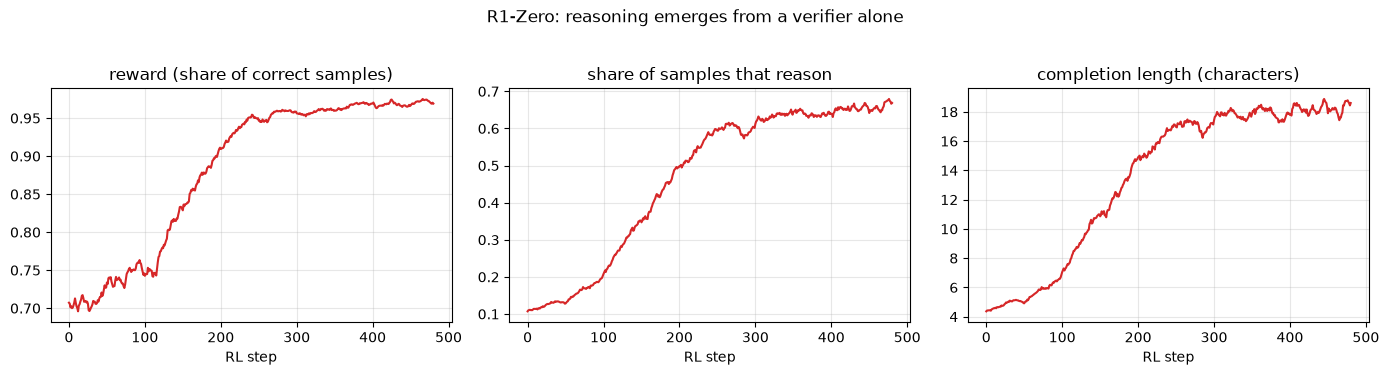

an answer of R1-Zero: :8-5=3,3+2=5,5+5=0,0*5=0,0*3=0>0$ | correct: 0
first RL step where the reward (25-step mean) reaches 90%: 217


on a 6-operation problem: 9*9-0-8-8*9-8= :9*9=1,1-0=1,1-8=3,3-8=5,5*9=5,5-8=7>7$ | correct: 7


In [5]:
zero = TransformerLM(CFG).to(device); zero.load_state_dict(BASE_STATE)
t0 = time.time(); ZERO_LOG = grpo(zero, RL_STEPS)
print(f"R1-Zero: {RL_STEPS} RL steps in {time.time() - t0:.0f} s")
RESULTS["R1-Zero"] = show("R1-Zero (GRPO from the base)", zero)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
sm = lambda xs, w=20: np.convolve(xs, np.ones(w) / w, mode="valid")
for a, key, title in zip(ax, ["reward", "reasons", "length"], ["reward (share of correct samples)", "share of samples that reason", "completion length (characters)"]):
    a.plot(sm([x[key] for x in ZERO_LOG]), color="tab:red"); a.set_title(title); a.set_xlabel("RL step"); a.grid(alpha=.3)
plt.suptitle("R1-Zero: reasoning emerges from a verifier alone", y=1.03); plt.tight_layout(); plt.show()
print("an answer of R1-Zero:", generate(zero, [render(TEST[1], "direct")[0]])[0], "| correct:", solve(TEST[1])[0])
sr = sm([x["reward"] for x in ZERO_LOG], 25)
print("first RL step where the reward (25-step mean) reaches 90%:", next((i + 25 for i, v in enumerate(sr) if v >= 0.9), "never"))
long_one = next(p for p in TEST if len(p) == 7)
print("on a 6-operation problem:", render(long_one, "direct")[0], generate(zero, [render(long_one, "direct")[0]])[0], "| correct:", solve(long_one)[0])

**What the numbers say.** With nothing but the verifier, RL turned a model that reasons on 11 % of its samples into one that reasons on most problems and gets nearly all of them right.

- **Accuracy: 69.4 % → 99.8 %** (+30.4 points, paired interval [+27.7, +33.1]). The reward (25-step mean) passes 90 % at step 217.
- **The behaviour moved with the reward.** The share of samples that reason climbs from 11 % to 67 %, and the mean answer length from 4.4 to 18.7 characters: "thinking longer", here, is writing out the steps. Nobody asked for it; reasoning was simply the behaviour that scored better than its siblings in each group.
- **It reasons where it needs to.** Section 7 shows the share of answers that reason by chain length: 0 % on one operation, 39 % on two, about 80 % from four operations on. It skips the steps where a direct answer is reliable, and the answers it gives directly are also right. That is the small-scale version of a reasoning model spending more tokens on harder problems.
- **The signal runs out as the model improves.** The share of groups with no signal (all 8 samples right, or all wrong) rises from 53 % to 80 %: once a problem is always solved, it teaches nothing. Real RL pipelines filter or reweight problems for this reason (DAPO's dynamic sampling, for example).
- The KL to the starting model stays small (about 0.05 per token): RL changed *which* behaviour the model picks more than what it knows.

The example answers use the format the 10 % of worked solutions taught. What did not appear is self-correction; at 1.6M parameters and on this task we did not expect it.

## 5. Cold start: SFT on 300 worked solutions

The R1 route: before any RL, a small supervised set of worked solutions, here 300 fresh problems, trained for 200 steps of 64.

In [6]:
SFT_SET = fresh(300)
sft = TransformerLM(CFG).to(device); sft.load_state_dict(BASE_STATE)
train(sft, lambda bs: [(random.choice(SFT_SET), "trace") for _ in range(bs)], 200, 2e-4, bs=64)
SFT_STATE = copy.deepcopy(sft.state_dict())
RESULTS["SFT"] = show("SFT on 300 worked solutions", sft)

SFT on 300 worked solutions          accuracy 100.0% [100.0%, 100.0%] | reasons 100% | length  24.1 | 8-10 operations: 15.0%


**What the numbers say.** 200 steps of SFT on 300 worked solutions take the base to **100.0 %** on the test set: the model now always reasons (answers of 24.1 characters on average), and the skill it already had does the rest. This is the cold start doing its job, fixing the *format* cheaply. R1-Zero needed about 217 RL steps, of 256 samples each, to pass 90 % reward.

## 6. R1: RL after the cold start, against a control

The same 500 GRPO steps, now from the SFT model. The **control** starts from the same SFT model and spends a comparable budget of gradient steps on more SFT over the same 300 solutions. If R1 beats the control, the gain comes from learning from the verifier on new problems, not from training longer.

In [7]:
r1 = TransformerLM(CFG).to(device); r1.load_state_dict(SFT_STATE)
t0 = time.time(); R1_LOG = grpo(r1, RL_STEPS)
print(f"R1: {RL_STEPS} RL steps in {time.time() - t0:.0f} s")
RESULTS["R1"] = show("R1 (SFT, then GRPO)", r1)

ctrl = TransformerLM(CFG).to(device); ctrl.load_state_dict(SFT_STATE)
train(ctrl, lambda bs: [(random.choice(SFT_SET), "trace") for _ in range(bs)], RL_STEPS, 5e-5, bs=64)
RESULTS["control"] = show("control: more SFT, same steps", ctrl)

from llm_edu_suite.evaluation import paired_bootstrap_diff
for a, b in [("R1", "control"), ("R1", "SFT"), ("R1-Zero", "base"), ("R1", "R1-Zero")]:
    d, lo, hi = paired_bootstrap_diff(RESULTS[b][0]["ok"], RESULTS[a][0]["ok"])   # returns second - first
    print(f"{a} - {b}: {d:+.1%} [{lo:+.1%}, {hi:+.1%}]")

  step   0 | reward 0.980 | reasons  99% | length  25.3 | KL 0.0000 | groups with no signal  88%


  step  25 | reward 0.980 | reasons  99% | length  24.2 | KL 0.0002 | groups with no signal  86%


  step  50 | reward 0.978 | reasons  99% | length  24.1 | KL 0.0002 | groups with no signal  85%


  step  75 | reward 0.980 | reasons  99% | length  24.2 | KL 0.0002 | groups with no signal  86%


  step 100 | reward 0.985 | reasons 100% | length  24.0 | KL 0.0014 | groups with no signal  89%


  step 125 | reward 0.985 | reasons 100% | length  24.5 | KL 0.0080 | groups with no signal  89%


... (13 outputs left out)

  step 475 | reward 0.989 | reasons 100% | length  23.9 | KL 0.0007 | groups with no signal  92%


  step 499 | reward 0.988 | reasons 100% | length  24.2 | KL 0.0005 | groups with no signal  91%
R1: 500 RL steps in 555 s


R1 (SFT, then GRPO)                  accuracy 100.0% [100.0%, 100.0%] | reasons 100% | length  24.1 | 8-10 operations: 14.8%


control: more SFT, same steps        accuracy 100.0% [100.0%, 100.0%] | reasons 100% | length  24.1 | 8-10 operations: 16.6%
R1 - control: +0.0% [+0.0%, +0.0%]
R1 - SFT: +0.0% [+0.0%, +0.0%]
R1-Zero - base: +30.4% [+27.7%, +33.1%]
R1 - R1-Zero: +0.2% [+0.0%, +0.5%]


**What the numbers say.** R1, the control and the SFT model all score **100.0 %**, and the paired differences between them are zero. RL after the cold start had nothing left to learn: from the first step, 88 % of the groups gave no signal, and the reward stayed at about 0.98.

That is the honest result with this pretraining: when the base model already has the skill, both routes reach the ceiling, and the remaining difference is cost. It agrees with recent analyses (Yue et al., 2025) arguing that RL with verifiable rewards mostly brings out reasoning the base model already has, rather than teaching new reasoning.

**With a weaker base, the picture changes.** An earlier run of this notebook used half the pretraining (3,000 steps, 5 % worked solutions, chains of 3–6 operations). There, made to reason, the base got 71.7 % instead of 99.9 %, and the routes separated:

| earlier run, weaker pretraining | accuracy on 3–6 operations |
|---|---|
| base | 39.8 % |
| R1-Zero | 73.3 % |
| SFT on 300 worked solutions | 72.1 % |
| R1 (SFT, then GRPO) | **82.7 %** |
| control: more SFT, same steps | 72.8 % |

R1 beat the control by +9.9 points (paired interval [+7.2, +12.6]): when the SFT model still makes mistakes, the verifier has something to teach that repeating the same 300 solutions cannot. That run also showed why we changed the setup. With few worked solutions, the 1.6M model learned the steps unevenly across chain lengths: each step must find its operand in the prompt, at a distance that depends on the prompt's length, so its accuracy by length was erratic.

## 7. Where reasoning helps: accuracy by chain length

The same five models on 300 problems for each chain length from 1 to 10 operations. Lengths 1–6 are the training range; 7–10 were never seen. Next to accuracy, the share of answers that reason at each length.

accuracy    operations:     1     2     3     4     5     6     7     8     9    10
base                     100%   99%   73%   51%   45%   44%   31%   32%   23%   25%
R1-Zero                  100%  100%  100%  100%  100%   99%   22%   25%   20%   18%
SFT                      100%  100%  100%  100%  100%  100%   16%   20%   13%   12%
R1                       100%  100%  100%  100%  100%  100%   18%   19%   16%   14%
control                  100%  100%  100%  100%  100%  100%   18%   18%   16%   11%

share that reasons
base                       0%    0%    0%    1%    1%    2%    6%    8%   11%   12%
R1-Zero                    0%   39%   66%   79%   80%   80%   87%   85%   87%   87%
SFT                      100%  100%  100%  100%  100%  100%  100%  100%  100%  100%
R1                       100%  100%  100%  100%  100%  100%  100%  100%  100%  100%
control                  100%  100%  100%  100%  100%  100%  100%  100%  100%  100%


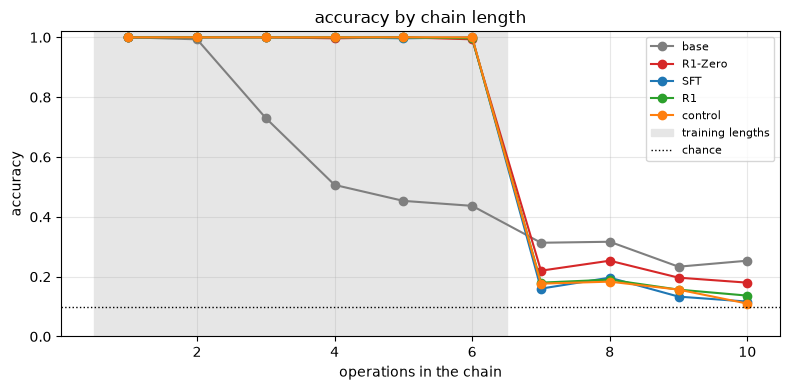

In [8]:
MODELS = {"base": base, "R1-Zero": zero, "SFT": sft, "R1": r1, "control": ctrl}
EVALS = {name: [evaluate(m, BY_LEN[k]) for k in range(1, 11)] for name, m in MODELS.items()}
CURVE = {name: [e["acc"] for e in ev] for name, ev in EVALS.items()}
print("accuracy    operations: " + " ".join(f"{k:>5d}" for k in range(1, 11)))
for name, accs in CURVE.items():
    print(f"{name:22s}  " + " ".join(f"{a:5.0%}" for a in accs))
print()
print("share that reasons")
for name, ev in EVALS.items():
    print(f"{name:22s}  " + " ".join(f"{e['reasons']:5.0%}" for e in ev))
fig, ax = plt.subplots(figsize=(8, 4))
for (name, accs), c in zip(CURVE.items(), ["tab:gray", "tab:red", "tab:blue", "tab:green", "tab:orange"]):
    ax.plot(range(1, 11), accs, "o-", color=c, label=name)
ax.axvspan(0.5, 6.5, color="0.9", zorder=0, label="training lengths"); ax.axhline(0.1, ls=":", color="k", lw=1, label="chance")
ax.set_xlabel("operations in the chain"); ax.set_ylabel("accuracy"); ax.set_ylim(0, 1.02); ax.legend(fontsize=8); ax.grid(alpha=.3)
ax.set_title("accuracy by chain length"); plt.tight_layout(); plt.show()

**What the numbers say.**

- **Inside the training range, reasoning removes the length problem.** The base model falls from 100 % at one operation to 44 % at six; every reasoning model stays at 99–100 % across all six lengths.
- **Outside it, nothing generalizes.** At 7–10 operations all reasoning models drop to 11–25 %, close to chance (10 %) and below the base (23–32 %). R1-Zero tries to reason on 85–87 % of these longer chains and still fails. The model learned to write *six steps or fewer*, not a procedure it can extend.
- **R1-Zero's adaptive reasoning is visible here too:** it reasons on 0 % of one-operation chains and about 80 % of the longer ones, while SFT, R1 and the control reason on 100 % of everything, because their SFT data always did.

Length generalization is a known weakness of transformers trained on arithmetic; it needs help from the position encoding or the data format (Zhou et al., 2024, with "index hints"; McLeish et al., 2024, with "Abacus" embeddings). We tried index hints, a label on each operation that the steps repeat: at this size it did worse, so it is not used here. For a language model the practical lesson is the same: train and evaluate on the lengths and difficulty you will meet.

## Results

| model (1.6M parameters, chains of 1–6 operations) | accuracy [95% CI] | reasons | answer length | 8–10 operations |
|---|---|---|---|---|
| base (pretrained, 10 % worked solutions) | 69.4 % [66.7, 72.1] | 1 % | 2.3 | 22.6 % |
| base, made to reason | 99.9 % | 100 % | | |
| **R1-Zero** (GRPO from the base, 500 steps) | **99.8 %** [99.5, 100] | 58 % | 17.6 | 18.2 % |
| SFT on 300 worked solutions | 100.0 % | 100 % | 24.1 | 15.0 % |
| R1 (SFT, then GRPO) | 100.0 % | 100 % | 24.1 | 14.8 % |
| control (more SFT, same steps) | 100.0 % | 100 % | 24.1 | 16.6 % |

What this establishes, at this scale:
- **Reasoning emerged from a verifier alone.** R1-Zero went from reasoning on 11 % of samples to 67 %, and from 69.4 % to 99.8 % accuracy (+30.4 points [+27.7, +33.1]), with no reasoning examples, and it learned to skip the steps on easy problems.
- **RL found a skill that pretraining had put there.** The base model, made to reason, already scored 99.9 %. RL changed the habit, not the knowledge.
- **The cold start reaches the same place far more cheaply** (200 SFT steps against about 217 RL steps of 256 samples to pass 90 %), and leaves RL nothing to add when the base is strong. With a weaker base (an earlier run), R1 beat its SFT starting point and a same-budget SFT control by about 10 points.
- **Reasoning did not generalize beyond the training lengths.** All reasoning models fall to 15–18 % on 8–10 operations, below the base.
- The whole notebook runs in about 30 minutes on a 6 GB laptop GPU: pretraining 567 s, each RL run about 550 s.

## In production

**What carries over from this toy.**
- RL with verifiable rewards works when the base model can already solve the task *sometimes*. Check that first with pass@k on the base (here, forcing the reasoning format gave 99.9 %); if pass@k is near zero, RL has no signal and you need better data or a better base.
- Track the share of groups with no signal. When it approaches 80–90 %, the batch is too easy (or too hard): filter problems by difficulty, as DAPO's dynamic sampling and most open recipes do.
- A small SFT cold start is the cheap way to fix format and readability; spend RL compute where SFT stops improving on a held-out set.
- Always compare against a same-budget SFT control. An RL gain that more SFT would also give is not a reason to run RL.
- Evaluate by difficulty and length, including lengths beyond training. An average hides both the cliff and the regions where nothing is left to learn.

**Doing it for real.**
- Libraries: TRL's `GRPOTrainer`, verl and OpenRLHF implement this loop at scale, with vLLM for sampling, several updates per batch with the clipped ratio, and LoRA or full fine-tuning (notebook 14).
- Rewards: unit tests for code, exact-match or symbolic checks for math, schema validators for structured output; a format reward alongside the correctness reward; and a watch for reward hacking (answers that pass the check without solving the task).
- Budget: sampling dominates the cost. Here the 500 RL steps sampled 128,000 answers; at LLM scale, that is where the GPUs go.
- For a small model, distillation (notebook 15's R1-Distill) is usually the better route: generate reasoning traces with a large reasoning model, keep the verified ones, and fine-tune the small model on them.

**Failure modes to watch.** Length growth without accuracy gain (the model learns that longer looks better), collapse of diversity within groups (no signal), reward hacking of a weak verifier, and forgetting of other skills when the KL grows.

**Next:** this is the last notebook. To go further, run the same recipe with TRL's `GRPOTrainer` on a small open model and a math or code verifier, starting from notebook 14.